In [113]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score
    )

In [114]:
data = pd.read_csv(r"C:\Users\VarunKarmikanda\msis\sem1\aml\aml\data\diabetes.csv")
dataset = data
dataset

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
...,...,...,...,...,...,...,...,...,...
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1


In [115]:
dataset.columns

Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'],
      dtype='object')

In [116]:
dataset.isnull().sum()

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

In [117]:
dataset.duplicated().sum()

np.int64(0)

In [118]:
# X = dataset.drop(['Outcome'], axis=1)
# X = dataset.drop('Outcome', axis=1)

X = dataset.drop(columns=['Outcome'])
X.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,6,148,72,35,0,33.6,0.627,50
1,1,85,66,29,0,26.6,0.351,31
2,8,183,64,0,0,23.3,0.672,32
3,1,89,66,23,94,28.1,0.167,21
4,0,137,40,35,168,43.1,2.288,33


In [119]:
# y = dataset['Outcome']
# y = dataset.iloc[:, -1]
# y = dataset.iloc[:, [-1]]

y = dataset[['Outcome']]
y.head()

,Outcome
0,1
1,0
2,1
3,0
4,1


In [120]:
sc = StandardScaler()
sc_X = sc.fit_transform(X)
sc_X

array([[ 0.63994726,  0.84832379,  0.14964075, ...,  0.20401277,
         0.46849198,  1.4259954 ],
       [-0.84488505, -1.12339636, -0.16054575, ..., -0.68442195,
        -0.36506078, -0.19067191],
       [ 1.23388019,  1.94372388, -0.26394125, ..., -1.10325546,
         0.60439732, -0.10558415],
       ...,
       [ 0.3429808 ,  0.00330087,  0.14964075, ..., -0.73518964,
        -0.68519336, -0.27575966],
       [-0.84488505,  0.1597866 , -0.47073225, ..., -0.24020459,
        -0.37110101,  1.17073215],
       [-0.84488505, -0.8730192 ,  0.04624525, ..., -0.20212881,
        -0.47378505, -0.87137393]], shape=(768, 8))

In [121]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

In [122]:
clasifier = DecisionTreeClassifier(criterion="entropy", random_state=0)
clasifier.fit(X_train, y_train)

DecisionTreeClassifier(criterion='entropy', random_state=0)

In [123]:
y_pred = clasifier.predict(X_test)

y_pred

array([1, 0, 0, 1, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0,
       0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 1, 1, 1, 0, 1, 1,
       0, 0, 0, 0, 1, 0, 0, 1, 1, 1, 0, 0, 1, 1, 0, 0, 0, 1, 0, 1, 1, 1,
       0, 0, 1, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 1,
       1, 0, 1, 1, 0, 0, 0, 0, 1, 1, 1, 1, 0, 0, 0, 0, 1, 1, 0, 1, 0, 1,
       0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0,
       0, 1, 1, 1, 1, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0])

In [124]:
y_test

,Outcome
661,1
122,0
113,0
14,1
529,0
...,...
476,1
482,0
230,1
527,0


In [125]:
cm = confusion_matrix(y_test, y_pred)
cm

array([[79, 28],
       [17, 30]])

In [128]:
accuracy = accuracy_score(y_test, y_pred)
accuracy * 100

70.77922077922078

In [130]:
precision = precision_score(y_test, y_pred)
precision

0.5172413793103449

In [133]:
cr = classification_report(y_test, y_pred)
print(cr)

              precision    recall  f1-score   support

           0       0.82      0.74      0.78       107
           1       0.52      0.64      0.57        47

    accuracy                           0.71       154
   macro avg       0.67      0.69      0.67       154
weighted avg       0.73      0.71      0.72       154



[Text(0.41510416666666666, 0.9722222222222222, 'x[1] <= 123.5\nentropy = 0.943\nsamples = 614\nvalue = [393.0, 221.0]'),
 Text(0.11215277777777778, 0.9166666666666666, 'x[5] <= 26.45\nentropy = 0.69\nsamples = 352\nvalue = [287, 65]'),
 Text(0.26362847222222224, 0.9444444444444444, 'True  '),
 Text(0.022222222222222223, 0.8611111111111112, 'x[6] <= 0.675\nentropy = 0.083\nsamples = 97\nvalue = [96, 1]'),
 Text(0.011111111111111112, 0.8055555555555556, 'entropy = 0.0\nsamples = 79\nvalue = [79, 0]'),
 Text(0.03333333333333333, 0.8055555555555556, 'x[6] <= 0.705\nentropy = 0.31\nsamples = 18\nvalue = [17, 1]'),
 Text(0.022222222222222223, 0.75, 'entropy = 0.0\nsamples = 1\nvalue = [0, 1]'),
 Text(0.044444444444444446, 0.75, 'entropy = 0.0\nsamples = 17\nvalue = [17, 0]'),
 Text(0.20208333333333334, 0.8611111111111112, 'x[7] <= 28.5\nentropy = 0.813\nsamples = 255\nvalue = [191, 64]'),
 Text(0.1, 0.8055555555555556, 'x[5] <= 30.95\nentropy = 0.549\nsamples = 134\nvalue = [117, 17]'),
 Tex

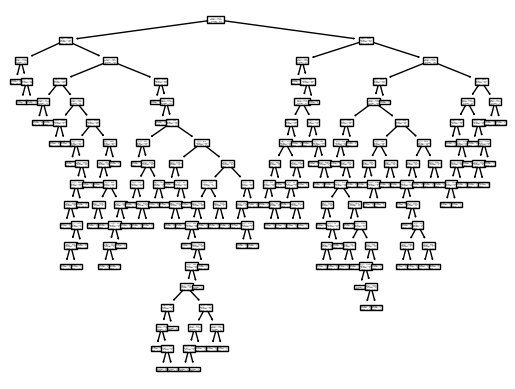

In [134]:
from sklearn import tree
tree.plot_tree(clasifier)